Vekil Model Sadakat (Fidelity) Skoru: %97.75


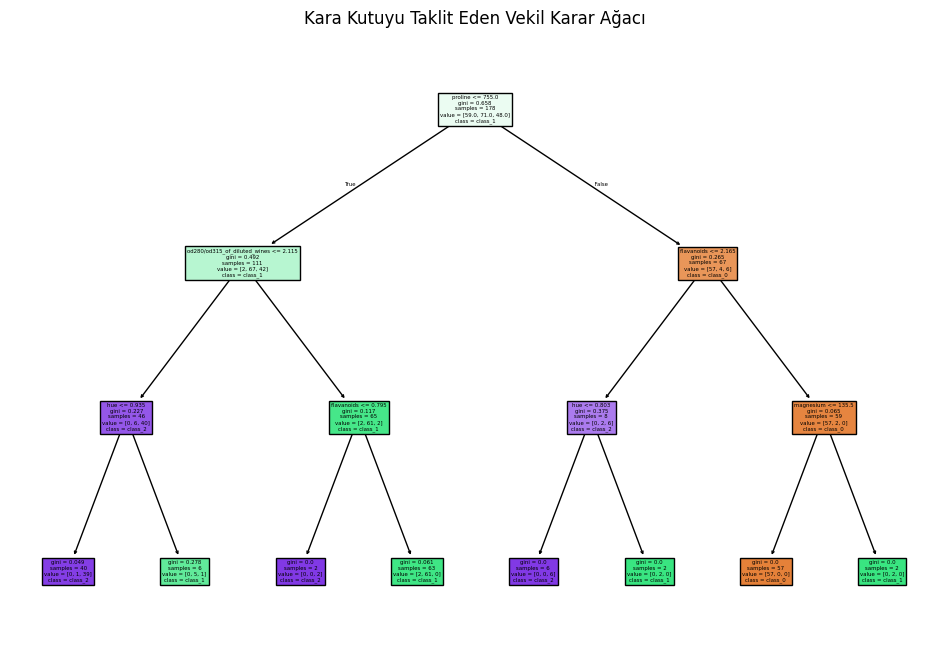

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Adım 1: Veri Kümesi X Seçimi
data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Adım 2: Kara Kutunun Eğitilmesi ve Tahminlerinin Alınması
black_box = RandomForestClassifier(n_estimators=100, random_state=42)
black_box.fit(X, y)
black_box_preds = black_box.predict(X)  # Kara kutu tahminleri

# Adım 3 & 4: Yorumlanabilir Model Seçimi ve Kara Kutunun Tahminleri Üzerinde Eğitimi
surrogate = DecisionTreeClassifier(max_depth=3, random_state=42)
surrogate.fit(X, black_box_preds)  # Orijinal 'y' yerine kara kutunun tahminleri kullanılıyor!

# Adım 5: Vekil Model Elde Edildi (surrogate)

# Adım 6: Vekilin Kara Kutuyu Ne Kadar İyi Taklit Ettiğinin Ölçülmesi ($R^2$ / Fidelity)
fidelity = accuracy_score(black_box_preds, surrogate.predict(X))
print(f"Vekil Model Sadakat (Fidelity) Skoru: %{fidelity * 100:.2f}")

# Adım 7: Vekili Yorumla
plt.figure(figsize=(12, 8))
plot_tree(surrogate, feature_names=X.columns, class_names=data.target_names, filled=True)
plt.title("Kara Kutuyu Taklit Eden Vekil Karar Ağacı")
plt.show()

